In [1]:
!pip install presidio-analyzer presidio-anonymizer spacy python-docx
!python -m spacy download en_core_web_lg

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 266.3/266.3 kB 3.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 253.0/253.0 kB 10.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.7/4.7 MB 20.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.6/2.6 MB 19.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 107.5/107.5 kB 4.6 MB/s eta 0:00:00
  Attempting uninstall: cryptography
    Found existing installation: cryptography 50.0.2
    Uninstalling cryptography-50.0.2:
      Successfully uninstalled cryptography-50.0.2
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
pyopenssl 26.4.0 requires cryptography<51,>=49.0.0, but you have cryptography 48.0.1 which is incompatible.
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 400.7/400.7 MB 1.4 MB/s eta 0:00:00
✔ Download and installation successful
You can now load the pa

# **import the necesscary libraries**

In [2]:
import re
import pandas as pd
import matplotlib.pyplot as plt
from collections import Counter
from presidio_analyzer import AnalyzerEngine, PatternRecognizer, Pattern, RecognizerRegistry
from presidio_anonymizer import AnonymizerEngine
from presidio_anonymizer.entities import OperatorConfig
import spacy
from spacy import displacy
from presidio_analyzer import AnalyzerEngine, PatternRecognizer, Pattern, RecognizerResult
from presidio_anonymizer import AnonymizerEngine
from presidio_anonymizer.entities import OperatorConfig
# Load spaCy model (md is lighter, lg is more accurate for NER)
nlp = spacy.load("en_core_web_lg")
# Presidio engines
analyzer = AnalyzerEngine()
anonymizer = AnonymizerEngine()
print("spaCy model:", nlp.meta["name"], "| pipeline:", nlp.pipe_names)


spaCy model: core_web_lg | pipeline: ['tok2vec', 'tagger', 'parser', 'attribute_ruler', 'lemmatizer', 'ner']


# **mount the google drive**

In [3]:
from google.colab import drive
import docx

# Mount Google Drive to the default directory
drive.mount('/content/drive')

# Define the correct path to your document
doc_path = '/content/drive/MyDrive/csvs_for_ML_work_notebooks/racistAI_report.docx'

# Load the document
try:
    doc = docx.Document(doc_path)
    print("Document loaded successfully! Paragraphs count:", len(doc.paragraphs))
except Exception as e:
    print(f"Could not load the document. Please verify the file path. Error: {e}")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Document loaded successfully! Paragraphs count: 89


# **Extract text from the `docx`**

In [5]:
def extract_docx_text(path: str) -> str:
    doc = docx.Document(path)
    lines = []
    for para in doc.paragraphs:
        lines.append(para.text)
    return "\n".join(lines)

# Using 'doc_path' which was defined in the setup cell
raw_text = extract_docx_text(doc_path)
print("Total characters:", len(raw_text))
print("\n--- First 800 chars ---\n")
print(raw_text[:800])

Total characters: 7742

--- First 800 chars ---

Uncovering the AI bias, It’s Roots and the Mitigation for a Fair Generative and Decision Making Systems
Aamir Khan
University of Westminster(The Westminster College Kupandole, Lalitpur)
aamir.ahmed.py@gmail.com






















Abstract
This paper dives into the permeating and widespread issue of biasness in Generative and Decision making AI systems. pulling form various multidisciplinary fields such as technical analysis, real-life case studies, policy making and discussions, this journal unmasks and outlines how biasness can originate form structural and logical models, training data, institutional practices to name a few. It outlines the importance of ethical and socio-economical consequences of biased AI deployment.
Putting a major impact on discussing mitigation strategies, highl


# **Epoaching:** split the documents into sections

the page has many markups and markdowns

In [6]:
def epoch_by_page(text: str):
    """Split on '===== Page N =====' markers. Keeps page number."""
    parts = re.split(r"={3,}\s*Page\s+(\d+)\s*={3,}", text)
    # parts = [before, '1', content1, '2', content2, ...]
    epochs = []
    if parts[0].strip():
        epochs.append({"epoch_id": "pre", "text": parts[0].strip()})
    for i in range(1, len(parts), 2):
        page_num = parts[i]
        content = parts[i+1].strip() if i+1 < len(parts) else ""
        if content:
            epochs.append({"epoch_id": f"page_{page_num}", "text": content})
    return epochs


def epoch_by_header(text: str):
    """Split on markdown-style headers (#, ##, ###)."""
    pattern = r"^(#{1,6})\s+(.+)$"
    lines = text.split("\n")
    epochs, current_title, current_lines = [], "PREAMBLE", []
    for line in lines:
        m = re.match(pattern, line)
        if m:
            if current_lines:
                epochs.append({
                    "epoch_id": current_title,
                    "text": "\n".join(current_lines).strip()
                })
            current_title = m.group(2).strip()
            current_lines = []
        else:
            current_lines.append(line)
    if current_lines:
        epochs.append({"epoch_id": current_title,
                       "text": "\n".join(current_lines).strip()})
    return [e for e in epochs if e["text"]]


page_epochs = epoch_by_page(raw_text)
header_epochs = epoch_by_header(raw_text)

print(f"Page epochs: {len(page_epochs)}")
print(f"Header epochs: {len(header_epochs)}")
print("\nHeader epoch titles:")
for e in header_epochs:
    print(" -", e["epoch_id"])

Page epochs: 1
Header epochs: 1

Header epoch titles:
 - PREAMBLE


# **PII detection, anonymization and analysis:**

### deterministic pattrens for the documents

### *PII detectioon using Regular expression*

In [7]:
REGEX_PATTERNS = {
    "EMAIL":     r"[a-zA-Z0-9._%+-]+@[a-zA-Z0-9.-]+\.[a-zA-Z]{2,}",
    "URL":       r"https?://[^\s>\]]+",
    "DOI":       r"10\.\d{4,9}/[-._;()/:A-Za-z0-9]+",
    "DATE":      r"(?:Jan|Feb|Mar|Apr|May|Jun|Jul|Aug|Sep|Oct|Nov|Dec)[a-z]*\.?\s+\d{1,2},\s+\d{4}",
    "CITATION":  r"\[\d+\]",
    "PAGE_MARK": r"={3,}\s*Page\s+\d+\s*={3,}",
}

def regex_find(text: str):
    hits = []
    for label, pat in REGEX_PATTERNS.items():
        for m in re.finditer(pat, text):
            hits.append({
                "entity_type": f"REGEX_{label}",
                "start": m.start(),
                "end": m.end(),
                "score": 1.0,
                "text": m.group(),
            })
    return hits

# quick test on the whole doc
regex_hits = regex_find(raw_text)
df_regex = pd.DataFrame(regex_hits)
print("Regex PII counts by type:")
print(df_regex["entity_type"].value_counts())
df_regex.head(15)

Regex PII counts by type:
entity_type
REGEX_URL         6
REGEX_CITATION    5
REGEX_DATE        5
REGEX_EMAIL       1
REGEX_DOI         1
Name: count, dtype: int64


,entity_type,start,end,score,text
0,REGEX_EMAIL,186,210,1.0,aamir.ahmed.py@gmail.com
1,REGEX_URL,6666,6734,1.0,https://www.sapien.io/blog/bias-in-ai-models-a...
2,REGEX_URL,6950,6993,1.0,https://doi.org/10.1057/s41599-023-02079-x.
3,REGEX_URL,7005,7055,1.0,https://www.nature.com/articles/s41599-023-020...
4,REGEX_URL,7169,7228,1.0,https://www.ericsson.com/en/blog/2021/11/ai-bi...
5,REGEX_URL,7406,7536,1.0,https://www.brookings.edu/articles/algorithmic...
6,REGEX_URL,7647,7714,1.0,https://www.sap.com/austria/blogs/can-ai-fix-t...
7,REGEX_DOI,6966,6993,1.0,10.1057/s41599-023-02079-x.
8,REGEX_DATE,6641,6653,1.0,"May 20, 2025"
9,REGEX_DATE,6747,6760,1.0,"Jun. 18, 2025"


### *MS Presidio analyser setup*

In [8]:
analyzer = AnalyzerEngine()

# Presidio's built-in URL/email recognizers already exist, but they can be noisy.
# We'll keep the default set and add spaCy-driven PERSON/ORG/LOC via the NLP engine.
SUPPORTED_ENTITIES = [
    "PERSON", "EMAIL_ADDRESS", "URL",
    "LOCATION", "DATE_TIME", "PHONE_NUMBER",
    "NRP", "ORGANIZATION",  # ORGANIZATION needs a custom recognizer (see next cell)
]

Presidio's default analyzer does not return `ORGANIZATION`. This small recognizer fixes that, so `Amazon`, `SAP`, `Ericsson`, Brookings get caught.

In [11]:
from presidio_analyzer import EntityRecognizer

class SpacyOrgRecognizer(EntityRecognizer):
    """Wraps spaCy ORG entities as a Presidio recognizer."""
    def __init__(self):
        super().__init__(
            supported_entities=["ORGANIZATION"],
            supported_language="en",
            name="SpacyOrgRecognizer"
        )
        self._nlp = nlp

    def analyze(self, text, entities, nlp_artifacts=None):
        results = []
        if "ORGANIZATION" not in entities:
            return results
        from presidio_analyzer import RecognizerResult
        doc = self._nlp(text)
        for ent in doc.ents:
            if ent.label_ == "ORG":
                results.append(RecognizerResult(
                    entity_type="ORGANIZATION",
                    start=ent.start_char,
                    end=ent.end_char,
                    score=0.85,
                ))
        return results


analyzer.registry.add_recognizer(SpacyOrgRecognizer())
print("Custom ORGANIZATION recognizer added.")

Custom ORGANIZATION recognizer added.


# **Run Presidio analysis per epoach**

In [12]:
def analyze_epoch(text: str):
    return analyzer.analyze(
        text=text,
        language="en",
        entities=SUPPORTED_ENTITIES,
    )

results_by_epoch = {}
for e in header_epochs:
    res = analyze_epoch(e["text"])
    results_by_epoch[e["epoch_id"]] = res

# Flatten for a DataFrame view
rows = []
for epoch_id, results in results_by_epoch.items():
    for r in results:
        rows.append({
            "epoch": epoch_id,
            "entity_type": r.entity_type,
            "start": r.start,
            "end": r.end,
            "score": round(r.score, 3),
            "text": header_epochs[[e["epoch_id"] for e in header_epochs].index(epoch_id)]["text"][r.start:r.end],
        })
df_presidio = pd.DataFrame(rows)
print("Presidio detections per epoch (top 20):")
df_presidio.head(20)

Presidio detections per epoch (top 20):


,epoch,entity_type,start,end,score,text
0,PREAMBLE,EMAIL_ADDRESS,186,210,1.00,aamir.ahmed.py@gmail.com
1,PREAMBLE,ORGANIZATION,15,17,0.85,AI
2,PREAMBLE,ORGANIZATION,80,103,0.85,Decision Making Systems
3,PREAMBLE,PERSON,104,125,0.85,Aamir Khan\nUniversity
4,PREAMBLE,ORGANIZATION,145,174,0.85,Westminster College Kupandole
5,PREAMBLE,PERSON,176,184,0.85,Lalitpur
6,PREAMBLE,ORGANIZATION,315,325,0.85,Generative
7,PREAMBLE,ORGANIZATION,1066,1068,0.85,AI
8,PREAMBLE,ORGANIZATION,1108,1116,0.85,blackbox
9,PREAMBLE,NRP,1541,1547,0.85,Sapien


# **Combine RegEx plus presidio with an overlapping resolution**

In [13]:
def merge_spans(regex_hits, presidio_results, text_len):
    """Combine both detection sets; longer span wins on overlap."""
    combined = []
    for h in regex_hits:
        combined.append({
            "entity_type": h["entity_type"],
            "start": h["start"], "end": h["end"],
            "score": h["score"], "source": "regex",
        })
    for r in presidio_results:
        combined.append({
            "entity_type": r.entity_type,
            "start": r.start, "end": r.end,
            "score": r.score, "source": "presidio",
        })
    # sort by start, then longest first
    combined.sort(key=lambda x: (x["start"], -(x["end"] - x["start"])))
    # drop overlaps
    kept, last_end = [], -1
    for span in combined:
        if span["start"] >= last_end:
            kept.append(span)
            last_end = span["end"]
    return kept


merged_by_epoch = {}
for e in header_epochs:
    regex_hits_e = regex_find(e["text"])
    presidio_res_e = results_by_epoch[e["epoch_id"]]
    merged_by_epoch[e["epoch_id"]] = merge_spans(
        regex_hits_e, presidio_res_e, len(e["text"])
    )

for k, v in merged_by_epoch.items():
    print(f"{k}: {len(v)} merged PII spans")

PREAMBLE: 58 merged PII spans


# **Anonymization with Presidio**

In [14]:
from presidio_anonymizer.entities import RecognizerResult as AnonRecognizerResult

anonymizer = AnonymizerEngine()

def anonymize_epoch(text: str, spans):
    # Presidio anonymizer expects RecognizerResult objects
    anon_inputs = [
        AnonRecognizerResult(
            entity_type=s["entity_type"],
            start=s["start"], end=s["end"], score=s["score"],
        )
        for s in spans
    ]
    return anonymizer.anonymize(
        text=text,
        analyzer_results=anon_inputs,
        operators={
            "DEFAULT": OperatorConfig("replace", {"new_value": "<REDACTED>"}),
            "REGEX_EMAIL": OperatorConfig("replace", {"new_value": "<EMAIL>"}),
            "EMAIL_ADDRESS": OperatorConfig("replace", {"new_value": "<EMAIL>"}),
            "REGEX_URL": OperatorConfig("replace", {"new_value": "<URL>"}),
            "URL": OperatorConfig("replace", {"new_value": "<URL>"}),
            "PERSON": OperatorConfig("replace", {"new_value": "<PERSON>"}),
            "ORGANIZATION": OperatorConfig("replace", {"new_value": "<ORG>"}),
            "LOCATION": OperatorConfig("replace", {"new_value": "<LOC>"}),
            "REGEX_CITATION": OperatorConfig("replace", {"new_value": "<CITE>"}),
        },
    ).text


anonymized_by_epoch = {
    k: anonymize_epoch(
        next(e["text"] for e in header_epochs if e["epoch_id"] == k),
        v
    )
    for k, v in merged_by_epoch.items()
}

# Preview one section
sample_key = list(anonymized_by_epoch.keys())[0]
print(f"--- Original: {sample_key} ---")
print(next(e["text"] for e in header_epochs if e["epoch_id"] == sample_key)[:400])
print(f"\n--- Anonymized ---")
print(anonymized_by_epoch[sample_key][:400])

--- Original: PREAMBLE ---
Uncovering the AI bias, It’s Roots and the Mitigation for a Fair Generative and Decision Making Systems
Aamir Khan
University of Westminster(The Westminster College Kupandole, Lalitpur)
aamir.ahmed.py@gmail.com






















Abstract
This paper dives into the permeating and widespread issue of biasness in Generative and Decision making AI systems. pulling form various multidisciplinary fie

--- Anonymized ---
Uncovering the <ORG> bias, It’s Roots and the Mitigation for a Fair Generative and <ORG>
<PERSON> of Westminster(The <ORG>, <PERSON>)
<EMAIL>






















Abstract
This paper dives into the permeating and widespread issue of biasness in <ORG> and Decision making AI systems. pulling form various multidisciplinary fields such as technical analysis, real-life case studies, policy making and 


# **Tokenization per epoach**

In [15]:
def spacy_tokenize(text: str):
    doc = nlp(text)
    return [
        {
            "text": t.text,
            "lemma": t.lemma_,
            "pos": t.pos_,
            "is_stop": t.is_stop,
            "is_punct": t.is_punct,
            "is_alpha": t.is_alpha,
        }
        for t in doc
    ]

token_stats = []
for e in header_epochs:
    orig_tokens = spacy_tokenize(e["text"])
    anon_tokens = spacy_tokenize(anonymized_by_epoch[e["epoch_id"]])
    token_stats.append({
        "epoch": e["epoch_id"],
        "orig_chars": len(e["text"]),
        "anon_chars": len(anonymized_by_epoch[e["epoch_id"]]),
        "orig_tokens": len(orig_tokens),
        "anon_tokens": len(anon_tokens),
        "token_delta": len(anon_tokens) - len(orig_tokens),
    })

df_tokens = pd.DataFrame(token_stats)
df_tokens

,epoch,orig_chars,anon_chars,orig_tokens,anon_tokens,token_delta
0,PREAMBLE,7740,7196,1306,1368,62


# **Analysing pii density per epoach**

In [16]:
density_rows = []
for e in header_epochs:
    k = e["epoch_id"]
    merged = merged_by_epoch[k]
    token_count = df_tokens.loc[df_tokens.epoch == k, "orig_tokens"].values[0]
    density_rows.append({
        "epoch": k,
        "chars": len(e["text"]),
        "tokens": token_count,
        "pii_spans": len(merged),
        "pii_per_1k_tokens": round(len(merged) / max(token_count, 1) * 1000, 2),
        "entity_types": ", ".join(sorted({s["entity_type"] for s in merged})),
    })

df_density = pd.DataFrame(density_rows).sort_values("pii_per_1k_tokens", ascending=False)
df_density

,epoch,chars,tokens,pii_spans,pii_per_1k_tokens,entity_types
0,PREAMBLE,7740,1306,58,44.41,"DATE_TIME, LOCATION, NRP, ORGANIZATION, PERSON..."


# **visual comparison**

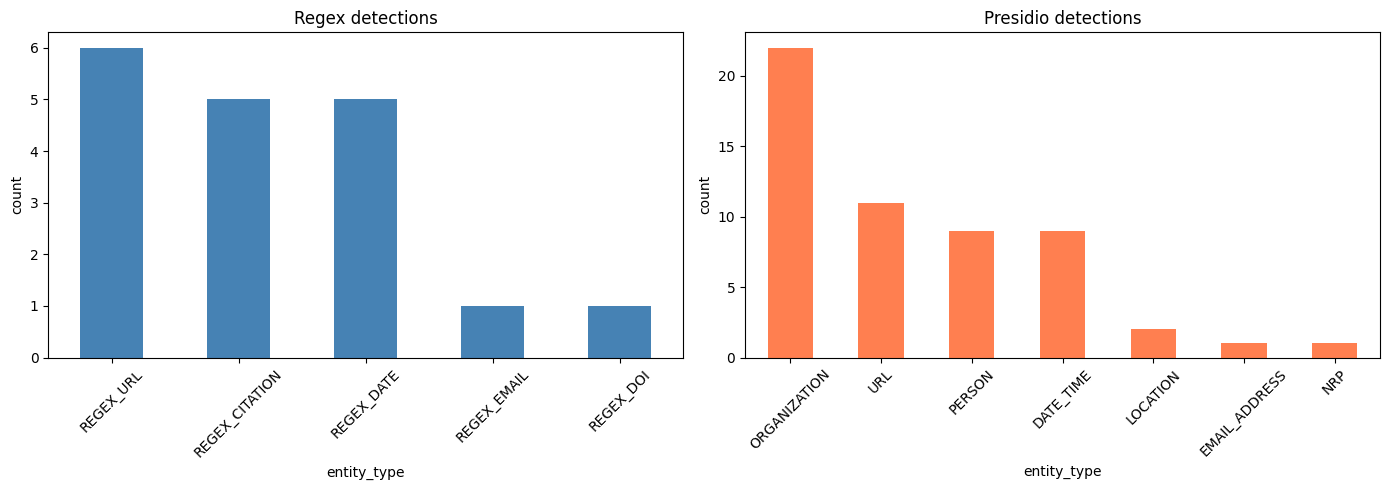

In [17]:
import matplotlib.pyplot as plt

# Count entity types per source
regex_counts = df_regex["entity_type"].value_counts()
presidio_counts = df_presidio["entity_type"].value_counts()

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
regex_counts.plot(kind="bar", ax=axes[0], color="steelblue", title="Regex detections")
presidio_counts.plot(kind="bar", ax=axes[1], color="coral", title="Presidio detections")
for ax in axes:
    ax.set_ylabel("count")
    ax.tick_params(axis="x", rotation=45)
plt.tight_layout()
plt.show()

# **Export the result:**

In [20]:
from pathlib import Path

OUT_DIR = Path("/content/drive/MyDrive/pii_output")
OUT_DIR.mkdir(parents=True, exist_ok=True)

# Merged PII report
rows = []
for k, spans in merged_by_epoch.items():
    for s in spans:
        rows.append({"epoch": k, **s})
pd.DataFrame(rows).to_csv(OUT_DIR / "pii_report.csv", index=False)

# Anonymized text
with open(OUT_DIR / "anonymized_report.txt", "w") as f:
    for k, txt in anonymized_by_epoch.items():
        f.write(f"\n===== {k} =====\n{txt}\n")

# Token stats
df_tokens.to_csv(OUT_DIR / "token_stats.csv", index=False)
df_density.to_csv(OUT_DIR / "pii_density.csv", index=False)

print("Exported to:", OUT_DIR)

Exported to: /content/drive/MyDrive/pii_output
